# 02. Authoritative Spatial Filtering & Data Quality Audit


## Section 1: Environment Setup and Portable Path Configuration

In [1]:
# Import standard library modules
import json
import math
from collections import Counter
from pathlib import Path

# Import core scientific and data analysis libraries
import numpy as np
import openpyxl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon

# Configure pandas display options for readable tables
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.precision", 3)

# Configure matplotlib visual styling
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8

# Define portable relative paths from the project working directory
if Path("Dataset/icnf_sgif/extracted").exists():
    raw_extracted_dir = Path("Dataset/icnf_sgif/extracted")
else:
    raw_extracted_dir = Path("data/raw/icnf_sgif/extracted")

if Path("data/reference/icnf_sgif/montesinho_boundary/montesinho_boundary_epsg3763.geojson").exists():
    boundary_path = Path("data/reference/icnf_sgif/montesinho_boundary/montesinho_boundary_epsg3763.geojson")
else:
    boundary_path = Path("Dataset/reference/icnf_sgif/montesinho_boundary/montesinho_boundary_epsg3763.geojson")

interim_dir = Path("data/interim/icnf_sgif")
tables_dir = Path("reports/tables/icnf_sgif")
figures_dir = Path("reports/figures/icnf_sgif")

# Ensure all output directories exist
for directory in [interim_dir, tables_dir, figures_dir]:
    directory.mkdir(parents=True, exist_ok=True)

# Discover the raw SGIF Excel workbooks
raw_workbooks = sorted(raw_extracted_dir.rglob("*.xlsx"))
print(f"Discovered raw SGIF workbooks: {len(raw_workbooks)}")
for wb in raw_workbooks:
    size_mb = wb.stat().st_size / (1024 * 1024)
    print(f" - {wb.name} ({size_mb:.2f} MB)")

print(f"Official boundary file: {boundary_path.as_posix()}")
print(f"Interim output folder : {interim_dir.as_posix()}")
print(f"Tables output folder  : {tables_dir.as_posix()}")
print(f"Figures output folder : {figures_dir.as_posix()}")


Discovered raw SGIF workbooks: 3
 - Registos_Incendios_SGIF_2001_2010.xlsx (83.17 MB)
 - Registos_Incendios_SGIF_2011_2020.xlsx (59.08 MB)
 - Registos_Incendios_SGIF_2021_2025.xlsx (13.86 MB)
Official boundary file: data/reference/icnf_sgif/montesinho_boundary/montesinho_boundary_epsg3763.geojson
Interim output folder : data/interim/icnf_sgif
Tables output folder  : reports/tables/icnf_sgif
Figures output folder : reports/figures/icnf_sgif


## Section 2: Loading and Inspecting the Official Montesinho Boundary


In [2]:
# Read and parse the official GeoJSON boundary file
with open(boundary_path, "r", encoding="utf-8-sig") as file_handle:
    boundary_geojson = json.load(file_handle)

features = boundary_geojson.get("features", [])
boundary_feature = features[0]
boundary_properties = boundary_feature["properties"]
boundary_geometry = boundary_feature["geometry"]
boundary_crs = boundary_geojson.get("crs", {}).get("properties", {}).get("name", "EPSG:3763")

# Normalize coordinates to a list of polygons (each polygon has an exterior ring and optional holes)
if boundary_geometry["type"] == "Polygon":
    boundary_polygons = [boundary_geometry["coordinates"]]
else:
    boundary_polygons = boundary_geometry["coordinates"]

# Collect all coordinate vertices using simple loops to compute the bounding box
all_boundary_vertices = []
for polygon in boundary_polygons:
    for ring in polygon:
        for point in ring:
            all_boundary_vertices.append(point)

x_coords = [pt[0] for pt in all_boundary_vertices]
y_coords = [pt[1] for pt in all_boundary_vertices]

boundary_bbox = {
    "minimum_x": min(x_coords),
    "minimum_y": min(y_coords),
    "maximum_x": max(x_coords),
    "maximum_y": max(y_coords),
}

# Construct and save the boundary metadata summary table
boundary_summary = pd.DataFrame([{
    "Park Name": boundary_properties["nome_ap"],
    "Official Code": boundary_properties["sigla"],
    "Classification": boundary_properties["classifica"],
    "Jurisdiction": boundary_properties["jurisdicao"],
    "Reported Area (ha)": boundary_properties["area_ha"],
    "CRS": boundary_crs,
    "Geometry Type": boundary_geometry["type"],
    "Polygon Count": len(boundary_polygons),
    "Total Vertices": len(all_boundary_vertices),
    "Min X (m)": round(boundary_bbox["minimum_x"], 2),
    "Min Y (m)": round(boundary_bbox["minimum_y"], 2),
    "Max X (m)": round(boundary_bbox["maximum_x"], 2),
    "Max Y (m)": round(boundary_bbox["maximum_y"], 2),
}])

boundary_summary_path = tables_dir / "montesinho_boundary_summary.csv"
boundary_summary.to_csv(boundary_summary_path, index=False)
print(f"Saved boundary summary table to: {boundary_summary_path.as_posix()}")
display(boundary_summary)


Saved boundary summary table to: reports/tables/icnf_sgif/montesinho_boundary_summary.csv


,Park Name,Official Code,Classification,Jurisdiction,Reported Area (ha),CRS,Geometry Type,Polygon Count,Total Vertices,Min X (m),Min Y (m),Max X (m),Max Y (m)
0,Montesinho,PNM,Parque Natural,ICNF,74224.89,EPSG:3763,Polygon,1,3985,77155.51,230368.1,134262.06,258949.66


## Section 3: Transparent Geometric Point-in-Polygon Engine


In [3]:
def point_on_segment(x, y, x1, y1, x2, y2, tolerance=1e-7):
    # Check if point (x, y) lies directly on segment (x1, y1)-(x2, y2)
    cross_product = (x - x1) * (y2 - y1) - (y - y1) * (x2 - x1)
    if abs(cross_product) > tolerance:
        return False
    within_x = (min(x1, x2) - tolerance) <= x <= (max(x1, x2) + tolerance)
    within_y = (min(y1, y2) - tolerance) <= y <= (max(y1, y2) + tolerance)
    return within_x and within_y


def point_in_ring(x, y, ring):
    # Test if point (x, y) is inside a closed polygon ring using ray-casting
    is_inside = False
    previous_vertex = ring[-1]

    for current_vertex in ring:
        x1, y1 = previous_vertex[0], previous_vertex[1]
        x2, y2 = current_vertex[0], current_vertex[1]

        if point_on_segment(x, y, x1, y1, x2, y2):
            return True

        # Check if horizontal ray to the right crosses the segment
        if (y1 > y) != (y2 > y):
            crossing_x = (x2 - x1) * (y - y1) / (y2 - y1) + x1
            if x < crossing_x:
                is_inside = not is_inside

        previous_vertex = current_vertex

    return is_inside


def point_in_polygon(x, y, polygon):
    # Test if point (x, y) lies inside the exterior ring and outside any interior holes
    if not point_in_ring(x, y, polygon[0]):
        return False
    for hole_ring in polygon[1:]:
        if point_in_ring(x, y, hole_ring):
            return False
    return True


def point_in_montesinho(x, y):
    # Determine if an ETRS89 coordinate (x, y) lies inside Parque Natural de Montesinho
    within_bbox = (
        boundary_bbox["minimum_x"] <= x <= boundary_bbox["maximum_x"]
        and boundary_bbox["minimum_y"] <= y <= boundary_bbox["maximum_y"]
    )
    if not within_bbox:
        return False

    for polygon in boundary_polygons:
        if point_in_polygon(x, y, polygon):
            return True
    return False


def point_to_segment_distance(px, py, x1, y1, x2, y2):
    # Calculate shortest Euclidean distance in meters from (px, py) to segment (x1, y1)-(x2, y2)
    dx = x2 - x1
    dy = y2 - y1
    if dx == 0 and dy == 0:
        return math.hypot(px - x1, py - y1)

    projection = ((px - x1) * dx + (py - y1) * dy) / (dx * dx + dy * dy)
    projection_clamped = max(0.0, min(1.0, projection))

    nearest_x = x1 + projection_clamped * dx
    nearest_y = y1 + projection_clamped * dy
    return math.hypot(px - nearest_x, py - nearest_y)


def distance_to_boundary(x, y):
    # Compute minimum Euclidean distance in meters from (x, y) to the park perimeter
    minimum_distance = float("inf")
    for polygon in boundary_polygons:
        for ring in polygon:
            for idx in range(len(ring)):
                previous = ring[idx - 1]
                current = ring[idx]
                dist = point_to_segment_distance(x, y, previous[0], previous[1], current[0], current[1])
                if dist < minimum_distance:
                    minimum_distance = dist
    return minimum_distance


# Quick sanity check on a known boundary vertex and the coordinate origin (0, 0)
sample_vertex = boundary_polygons[0][0][0]
print(f"Sanity check — Boundary vertex inside park : {point_in_montesinho(sample_vertex[0], sample_vertex[1])}")
print(f"Sanity check — Origin (0, 0) inside park   : {point_in_montesinho(0.0, 0.0)}")


Sanity check — Boundary vertex inside park : True
Sanity check — Origin (0, 0) inside park   : False


## Section 4: Scanning and Spatially Filtering the 2004–2025 National SGIF Workbooks


In [4]:
# Initialize counters and storage lists
spatial_counts = Counter()
core_records = []
spatial_disagreements = []
records_considered = 0
total_national_records = 0

# Scan each decadal workbook in read-only streaming mode
for workbook_path in raw_workbooks:
    workbook = openpyxl.load_workbook(workbook_path, read_only=True, data_only=True)
    event_sheet = workbook.worksheets[0]
    row_iterator = event_sheet.iter_rows(values_only=True)

    # Map column names to their zero-based index positions
    headers = list(next(row_iterator))
    column_index = {}
    for pos, col_name in enumerate(headers):
        column_index[col_name] = pos

    # Evaluate every row in the worksheet
    for excel_row_idx, row_values in enumerate(row_iterator, start=2):
        total_national_records += 1
        year_value = row_values[column_index["Ano"]]

        # Apply post-2003 temporal filter (Ano >= 2004)
        if not isinstance(year_value, (int, float)) or year_value < 2004:
            continue

        records_considered += 1

        # Extract ETRS89 coordinates and test polygon inclusion
        x_val = row_values[column_index["X_ETRS89"]]
        y_val = row_values[column_index["Y_ETRS89"]]
        has_numeric_coords = isinstance(x_val, (int, float)) and isinstance(y_val, (int, float))

        geometry_inside = False
        if has_numeric_coords:
            geometry_inside = point_in_montesinho(float(x_val), float(y_val))

        # Check whether the RNAP text column mentions Montesinho
        rnap_val = row_values[column_index["RNAP"]]
        tag_inside = False
        if rnap_val is not None and "montesinho" in str(rnap_val).casefold():
            tag_inside = True

        # Assign spatial agreement category
        if geometry_inside and tag_inside:
            agreement_group = "geometry_and_tag"
        elif geometry_inside:
            agreement_group = "geometry_only"
        elif tag_inside:
            agreement_group = "tag_only"
        else:
            agreement_group = "outside_both"

        spatial_counts[agreement_group] += 1

        # Retain all events inside the official boundary polygon
        if geometry_inside:
            record_dict = dict(zip(headers, row_values))
            record_dict["_source_workbook"] = workbook_path.name
            record_dict["_source_sheet"] = event_sheet.title
            record_dict["_source_excel_row"] = excel_row_idx
            record_dict["_inside_official_boundary"] = True
            record_dict["_rnap_montesinho_tag"] = tag_inside
            record_dict["_spatial_agreement_group"] = agreement_group
            core_records.append(record_dict)

        # Record any disagreement between coordinate geometry and text tag
        if agreement_group in {"geometry_only", "tag_only"}:
            dist_m = np.nan
            if has_numeric_coords:
                dist_m = round(distance_to_boundary(float(x_val), float(y_val)), 2)
            spatial_disagreements.append({
                "Codigo_SGIF": row_values[column_index["Codigo_SGIF"]],
                "Ano": int(year_value),
                "RNAP": rnap_val,
                "X_ETRS89": x_val,
                "Y_ETRS89": y_val,
                "agreement_group": agreement_group,
                "distance_to_boundary_m": dist_m,
                "source_workbook": workbook_path.name,
                "source_excel_row": excel_row_idx,
            })

    workbook.close()
    print(f"Completed scan of workbook: {workbook_path.name}")

# Convert collected records into pandas DataFrames
montesinho_core = pd.DataFrame(core_records)
spatial_disagreements_table = pd.DataFrame(spatial_disagreements)

print("\n" + "=" * 60)
print(f"Total National Records (2001-2025):     {total_national_records:,}")
print(f"Post-2003 Records Evaluated (>= 2004):   {records_considered:,}")
print(f"Inside Official Montesinho Boundary:     {len(montesinho_core):,}")
print("Spatial Agreement Breakdown:")
print(f" - Geometry and tag agree inside:        {spatial_counts['geometry_and_tag']:,}")
print(f" - Geometry inside; RNAP tag absent:     {spatial_counts['geometry_only']:,}")
print(f" - RNAP tag present; geometry outside:   {spatial_counts['tag_only']:,}")
print("=" * 60)

display(spatial_disagreements_table)


Completed scan of workbook: Registos_Incendios_SGIF_2001_2010.xlsx
Completed scan of workbook: Registos_Incendios_SGIF_2011_2020.xlsx
Completed scan of workbook: Registos_Incendios_SGIF_2021_2025.xlsx

Total National Records (2001-2025):     497,478
Post-2003 Records Evaluated (>= 2004):   411,483
Inside Official Montesinho Boundary:     1,644
Spatial Agreement Breakdown:
 - Geometry and tag agree inside:        1,641
 - Geometry inside; RNAP tag absent:     3
 - RNAP tag present; geometry outside:   1


,Codigo_SGIF,Ano,RNAP,X_ETRS89,Y_ETRS89,agreement_group,distance_to_boundary_m,source_workbook,source_excel_row
0,TM21664,2016,NaN,127071.686,240153.071,geometry_only,646.90,Registos_Incendios_SGIF_2011_2020.xlsx,109004
1,TM220227,2020,Montesinho,97912.359,255083.683,tag_only,0.20,Registos_Incendios_SGIF_2011_2020.xlsx,172519
2,2022_04_0009918,2022,NaN,101673.465,246734.074,geometry_only,4478.01,Registos_Incendios_SGIF_2021_2025.xlsx,10463
3,20240918936,2024,NaN,119493.024,238764.876,geometry_only,146.02,Registos_Incendios_SGIF_2021_2025.xlsx,28546


## Section 5: Spatial Audit Findings & Saving Audit Tables

In [5]:
# Construct the spatial filter summary table
spatial_filter_summary = pd.DataFrame([
    {"group": "Geometry and RNAP tag agree inside", "records": spatial_counts["geometry_and_tag"]},
    {"group": "Geometry inside; RNAP tag absent", "records": spatial_counts["geometry_only"]},
    {"group": "RNAP tag present; geometry outside", "records": spatial_counts["tag_only"]},
    {"group": "Core geometry-inside cohort", "records": len(montesinho_core)},
    {"group": "National post-2003 records checked", "records": records_considered},
])

# Save both spatial audit tables using relative paths
summary_csv_path = tables_dir / "spatial_filter_summary.csv"
disagreements_csv_path = tables_dir / "spatial_filter_disagreements.csv"
spatial_filter_summary.to_csv(summary_csv_path, index=False)
spatial_disagreements_table.to_csv(disagreements_csv_path, index=False)

print("Saved spatial audit tables:")
print(f" - {summary_csv_path.as_posix()}")
print(f" - {disagreements_csv_path.as_posix()}")

display(spatial_filter_summary)


Saved spatial audit tables:
 - reports/tables/icnf_sgif/spatial_filter_summary.csv
 - reports/tables/icnf_sgif/spatial_filter_disagreements.csv


,group,records
0,Geometry and RNAP tag agree inside,1641
1,Geometry inside; RNAP tag absent,3
2,RNAP tag present; geometry outside,1
3,Core geometry-inside cohort,1644
4,National post-2003 records checked,411483


## Section 6: Visualization 1 — Cohort Construction & Spatial Audit Breakdown


Saved cohort construction flow figure to: reports/figures/icnf_sgif/montesinho_cohort_construction_flow.png


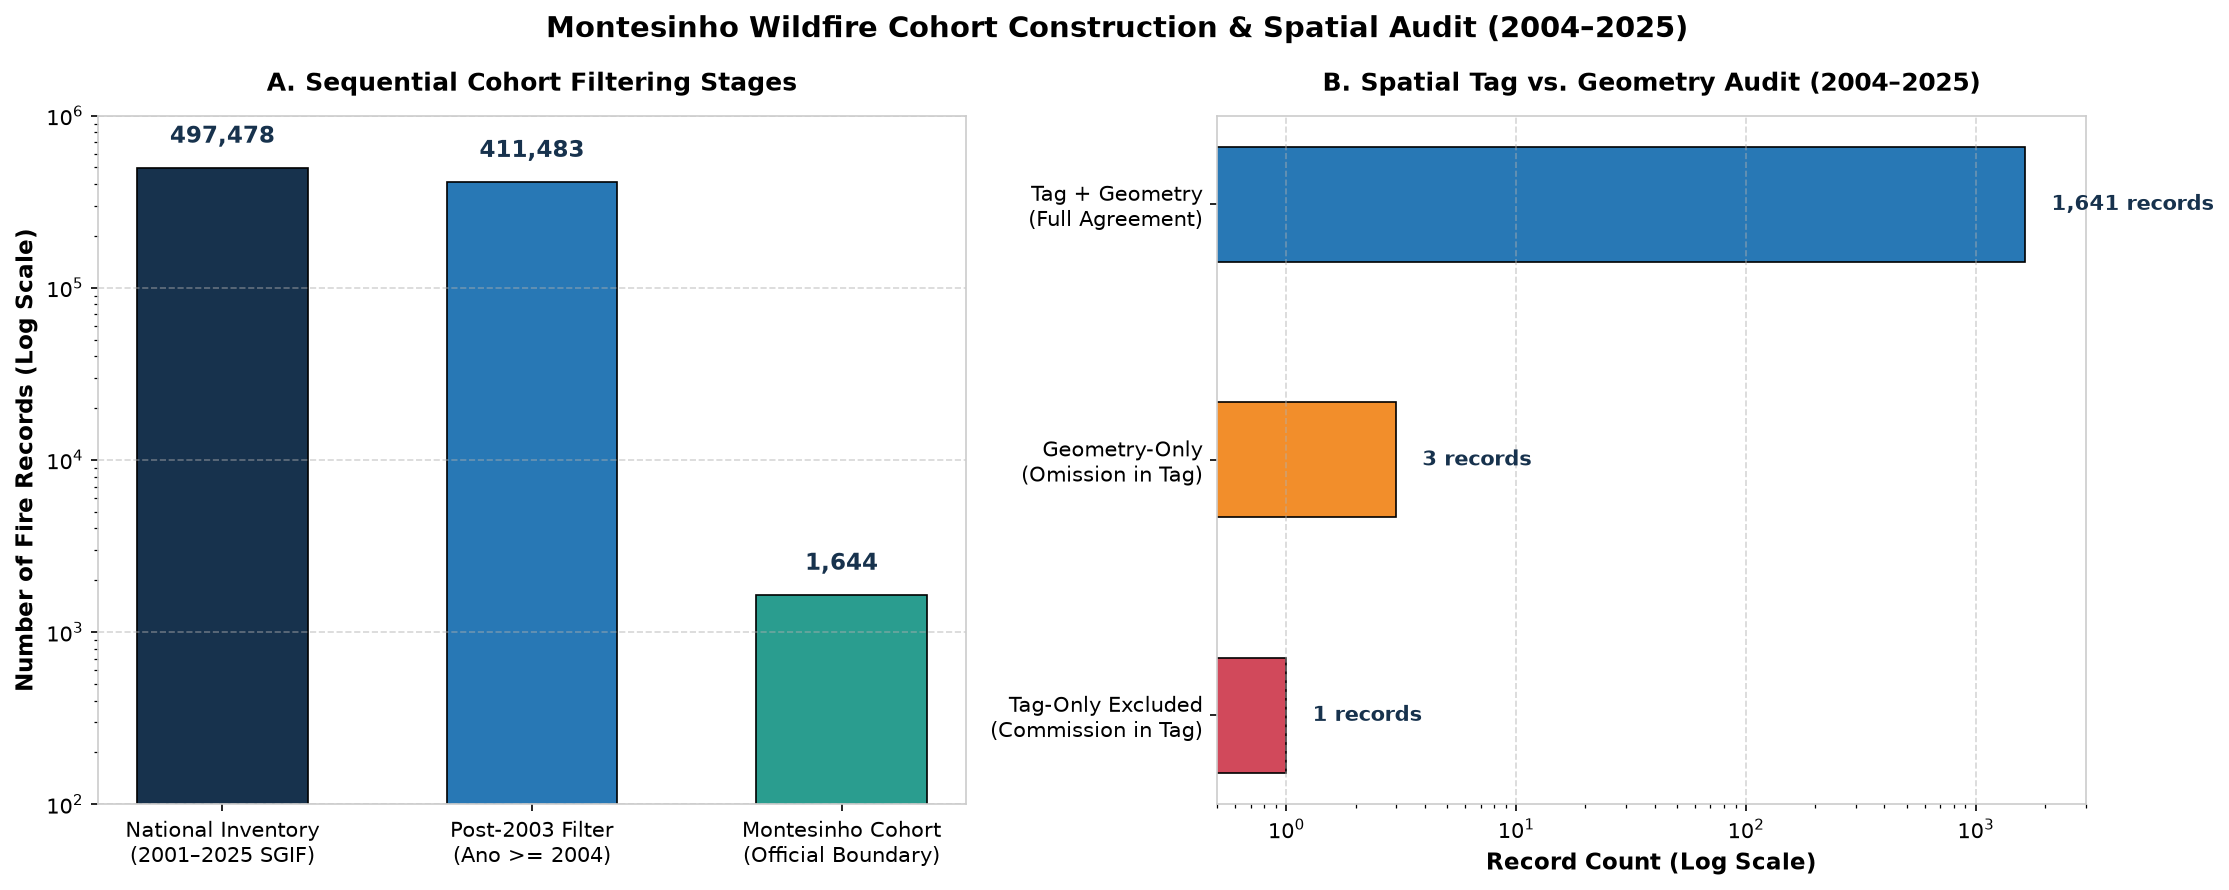

In [6]:
# Create a clean two-panel figure for the cohort construction flow
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Panel A: Sequential Filtering Stages ---
stages = [
    "National Inventory\n(2001–2025 SGIF)",
    "Post-2003 Filter\n(Ano >= 2004)",
    "Montesinho Cohort\n(Official Boundary)",
]
stage_counts = [total_national_records, records_considered, len(montesinho_core)]
stage_colors = ["#17324D", "#2878B5", "#2A9D8F"]

bars1 = ax1.bar(stages, stage_counts, color=stage_colors, width=0.55, edgecolor="black", linewidth=0.8)
ax1.set_title("A. Sequential Cohort Filtering Stages", fontsize=12, fontweight="bold", pad=12)
ax1.set_ylabel("Number of Fire Records (Log Scale)", fontsize=11, fontweight="bold")
ax1.set_yscale("log")
ax1.set_ylim(100, 1000000)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for bar, count in zip(bars1, stage_counts):
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height * 1.3,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#17324D",
    )

# --- Panel B: Spatial Tag vs. Geometry Audit ---
audit_labels = [
    "Tag-Only Excluded\n(Commission in Tag)",
    "Geometry-Only\n(Omission in Tag)",
    "Tag + Geometry\n(Full Agreement)",
]
audit_values = [
    spatial_counts["tag_only"],
    spatial_counts["geometry_only"],
    spatial_counts["geometry_and_tag"],
]
audit_colors = ["#D1495B", "#F28E2B", "#2878B5"]

bars2 = ax2.barh(audit_labels, audit_values, color=audit_colors, height=0.45, edgecolor="black", linewidth=0.8)
ax2.set_title("B. Spatial Tag vs. Geometry Audit (2004–2025)", fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel("Record Count (Log Scale)", fontsize=11, fontweight="bold")
ax2.set_xscale("log")
ax2.set_xlim(0.5, 3000)
ax2.grid(axis="x", linestyle="--", alpha=0.5)

for bar, count in zip(bars2, audit_values):
    width = bar.get_width()
    ax2.text(
        width * 1.3,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} records",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#17324D",
    )

plt.suptitle("Montesinho Wildfire Cohort Construction & Spatial Audit (2004–2025)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()

cohort_flow_path = figures_dir / "montesinho_cohort_construction_flow.png"
plt.savefig(cohort_flow_path, dpi=300)
print(f"Saved cohort construction flow figure to: {cohort_flow_path.as_posix()}")
plt.show()


## Section 7: Visualization 2 — Spatial Map of Official Boundary and Ignition Points


Saved spatial filter map figure to: reports/figures/icnf_sgif/montesinho_spatial_filter_map.png


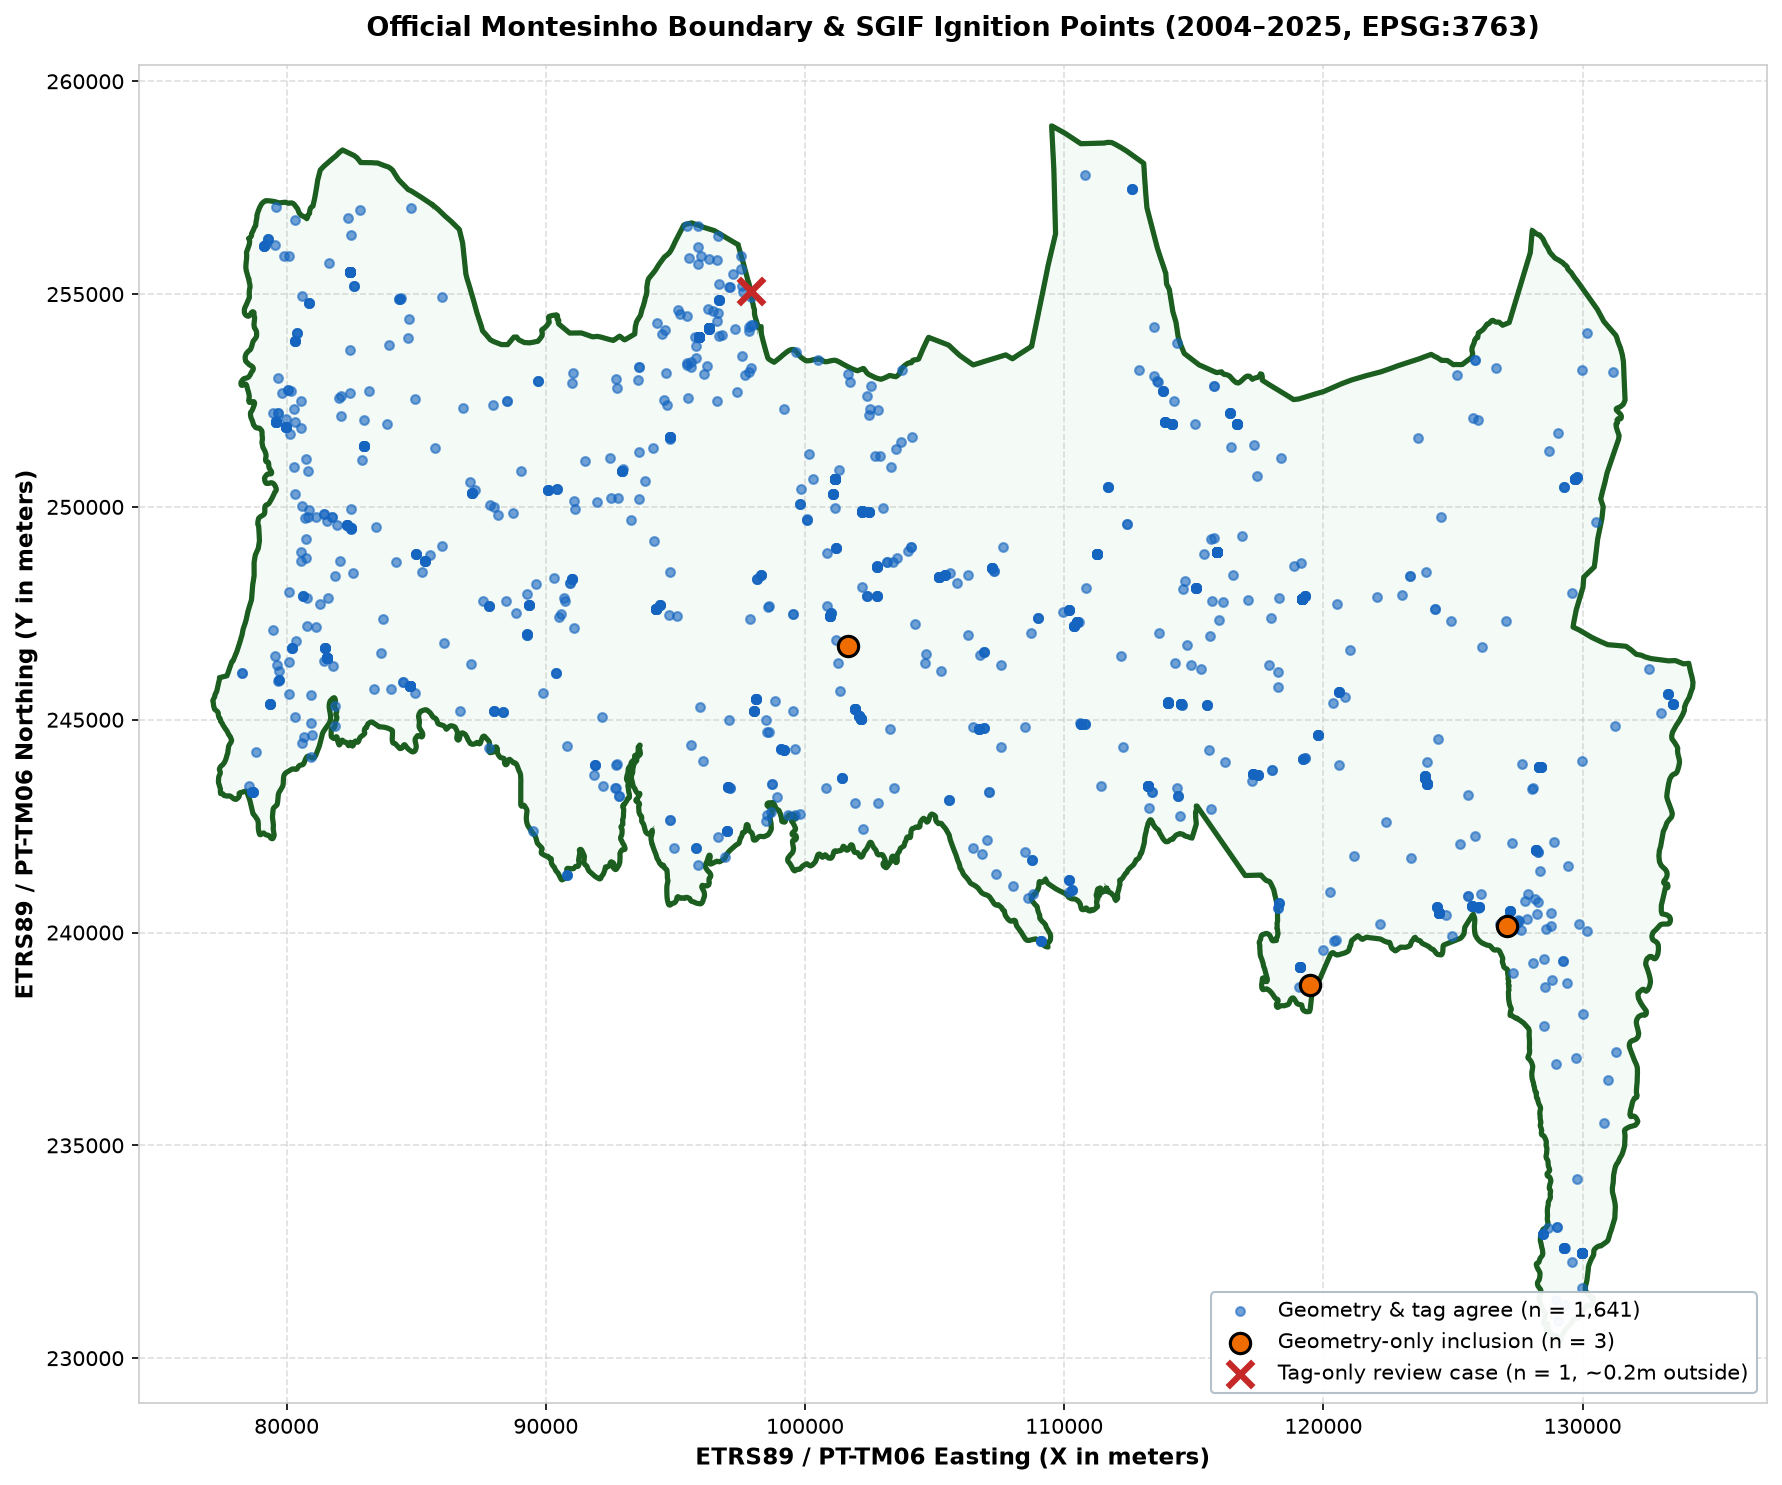

In [7]:
# Create the spatial boundary and ignition map figure
fig, ax = plt.subplots(figsize=(12, 10))

# 1. Draw the official Montesinho boundary polygon
for polygon in boundary_polygons:
    exterior_ring = polygon[0]
    ring_x = [pt[0] for pt in exterior_ring]
    ring_y = [pt[1] for pt in exterior_ring]
    ax.plot(ring_x, ring_y, color="#1B5E20", linewidth=2.5, zorder=2)
    polygon_patch = MplPolygon(
        exterior_ring,
        closed=True,
        facecolor="#E8F5E9",
        edgecolor="#1B5E20",
        linewidth=2,
        alpha=0.45,
        zorder=1,
    )
    ax.add_patch(polygon_patch)

# 2. Subset ignition points by spatial agreement group
agreed_events = montesinho_core[montesinho_core["_spatial_agreement_group"] == "geometry_and_tag"]
geometry_only_events = montesinho_core[montesinho_core["_spatial_agreement_group"] == "geometry_only"]
tag_only_cases = spatial_disagreements_table[spatial_disagreements_table["agreement_group"] == "tag_only"]

ax.scatter(
    agreed_events["X_ETRS89"],
    agreed_events["Y_ETRS89"],
    c="#1565C0",
    s=18,
    alpha=0.6,
    label=f"Geometry & tag agree (n = {len(agreed_events):,})",
    zorder=3,
)

ax.scatter(
    geometry_only_events["X_ETRS89"],
    geometry_only_events["Y_ETRS89"],
    c="#EF6C00",
    s=95,
    edgecolors="black",
    linewidth=1.5,
    label=f"Geometry-only inclusion (n = {len(geometry_only_events)})",
    zorder=4,
)

ax.scatter(
    tag_only_cases["X_ETRS89"],
    tag_only_cases["Y_ETRS89"],
    c="#C62828",
    s=150,
    marker="x",
    linewidth=3,
    label=f"Tag-only review case (n = {len(tag_only_cases)}, ~0.2m outside)",
    zorder=5,
)

ax.set_title("Official Montesinho Boundary & SGIF Ignition Points (2004–2025, EPSG:3763)", fontsize=13, fontweight="bold", pad=14)
ax.set_xlabel("ETRS89 / PT-TM06 Easting (X in meters)", fontsize=11, fontweight="bold")
ax.set_ylabel("ETRS89 / PT-TM06 Northing (Y in meters)", fontsize=11, fontweight="bold")
ax.ticklabel_format(style="plain", useOffset=False)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower right", frameon=True, framealpha=0.95, facecolor="white", edgecolor="#B0BEC5", fontsize=10)

plt.tight_layout()

spatial_map_path = figures_dir / "montesinho_spatial_filter_map.png"
plt.savefig(spatial_map_path, dpi=300)
print(f"Saved spatial filter map figure to: {spatial_map_path.as_posix()}")
plt.show()


## Section 8: Data Quality & Integrity Audit


In [8]:
# Define essential operational fields and the 7 FWI indices
essential_fields = [
    "Codigo_SGIF", "Ano", "DataHoraAlerta", "AreaTotal_ha",
    "X_ETRS89", "Y_ETRS89", "Latitude", "Longitude",
]
fwi_fields = ["FFMC", "DMC", "DC", "ISI", "BUI", "FWI", "DSR"]

# Parse timestamp columns into datetime objects
for date_col in ["DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao"]:
    montesinho_core[date_col] = pd.to_datetime(montesinho_core[date_col], errors="coerce")

# Compute vegetation sub-area sum and absolute difference against AreaTotal_ha
montesinho_core["_area_component_sum_ha"] = (
    montesinho_core["AreaPov_ha"]
    + montesinho_core["AreaMato_ha"]
    + montesinho_core["AreaAgric_ha"]
)
montesinho_core["_area_component_difference_ha"] = (
    montesinho_core["AreaTotal_ha"] - montesinho_core["_area_component_sum_ha"]
).abs()

# Create explicit boolean audit flags
montesinho_core["_complete_fwi"] = montesinho_core[fwi_fields].notna().all(axis=1)
montesinho_core["_essential_fields_complete"] = montesinho_core[essential_fields].notna().all(axis=1)
montesinho_core["_nonnegative_target"] = montesinho_core["AreaTotal_ha"] >= 0
montesinho_core["_model_eligible_basic"] = (
    montesinho_core["_essential_fields_complete"]
    & montesinho_core["_nonnegative_target"]
    & (montesinho_core["_area_component_difference_ha"] <= 0.011)
)

# Count quality anomalies across the cohort
duplicate_id_rows = int(montesinho_core.duplicated("Codigo_SGIF").sum())
negative_area_rows = int((montesinho_core["AreaTotal_ha"] < 0).sum())
area_disagreement_rows = int((montesinho_core["_area_component_difference_ha"] > 0.011).sum())
year_mismatch_rows = int((montesinho_core["DataHoraAlerta"].dt.year != montesinho_core["Ano"]).sum())

extinction_before_alert = (
    montesinho_core["DataHora_Extincao"].notna()
    & (montesinho_core["DataHora_Extincao"] < montesinho_core["DataHoraAlerta"])
)
intervention_before_alert = (
    montesinho_core["DataHora_PrimeiraIntervencao"].notna()
    & (montesinho_core["DataHora_PrimeiraIntervencao"] < montesinho_core["DataHoraAlerta"])
)

# Check FWI physical bounds (>= 0 and FFMC <= 101)
invalid_fwi = pd.Series(False, index=montesinho_core.index)
for col in fwi_fields:
    invalid_fwi = invalid_fwi | (montesinho_core[col] < 0)
invalid_fwi = invalid_fwi | (montesinho_core["FFMC"] > 101)

# Build field-by-field missingness table using a clear loop
missingness_rows = []
for field in essential_fields + fwi_fields:
    missing_cnt = int(montesinho_core[field].isna().sum())
    missing_pct = float(montesinho_core[field].isna().mean() * 100.0)
    missingness_rows.append({
        "field": field,
        "missing_records": missing_cnt,
        "missing_percentage": missing_pct,
    })
essential_missingness = pd.DataFrame(missingness_rows)

# Build the 10-point Cleaning Quality Audit Summary table
cleaning_quality_summary = pd.DataFrame([
    {"check": "Core records", "records": len(montesinho_core)},
    {"check": "Duplicate SGIF ID rows", "records": duplicate_id_rows},
    {"check": "Rows missing any essential field", "records": int((~montesinho_core["_essential_fields_complete"]).sum())},
    {"check": "Negative target rows", "records": negative_area_rows},
    {"check": "Area-component disagreements above 0.011 ha", "records": area_disagreement_rows},
    {"check": "Alert-year mismatches", "records": year_mismatch_rows},
    {"check": "Rows missing one or more FWI fields", "records": int((~montesinho_core["_complete_fwi"]).sum())},
    {"check": "Rows with invalid FWI ranges", "records": int(invalid_fwi.sum())},
    {"check": "Extinction before alert", "records": int(extinction_before_alert.sum())},
    {"check": "First intervention before alert", "records": int(intervention_before_alert.sum())},
    {"check": "Basic model-eligible records", "records": int(montesinho_core["_model_eligible_basic"].sum())},
])

# Extract timestamp anomaly and missing-FWI audit tables
timestamp_anomalies = montesinho_core.loc[
    extinction_before_alert | intervention_before_alert,
    [
        "Codigo_SGIF", "Ano", "DataHoraAlerta",
        "DataHora_PrimeiraIntervencao", "DataHora_Extincao",
        "Duracao_Horas", "_source_workbook", "_source_excel_row",
    ],
].copy()

fwi_missing_rows = montesinho_core.loc[
    ~montesinho_core["_complete_fwi"],
    ["Codigo_SGIF", "Ano", *fwi_fields, "_source_workbook", "_source_excel_row"],
].copy()

# Save all four quality audit tables
cleaning_quality_summary.to_csv(tables_dir / "cleaning_quality_summary.csv", index=False)
essential_missingness.to_csv(tables_dir / "essential_and_fwi_missingness.csv", index=False)
timestamp_anomalies.to_csv(tables_dir / "timestamp_anomalies.csv", index=False)
fwi_missing_rows.to_csv(tables_dir / "fwi_missing_rows.csv", index=False)

print("Cleaning Quality Audit Summary:")
display(cleaning_quality_summary)

print("\nMissingness across Essential & FWI Fields:")
display(essential_missingness)

print("\nRecords Missing FWI Fields:")
display(fwi_missing_rows)


Cleaning Quality Audit Summary:


,check,records
0,Core records,1644
1,Duplicate SGIF ID rows,0
2,Rows missing any essential field,0
3,Negative target rows,0
4,Area-component disagreements above 0.011 ha,0
5,Alert-year mismatches,0
6,Rows missing one or more FWI fields,3
7,Rows with invalid FWI ranges,0
8,Extinction before alert,0
9,First intervention before alert,0



Missingness across Essential & FWI Fields:


,field,missing_records,missing_percentage
0,Codigo_SGIF,0,0.000
1,Ano,0,0.000
2,DataHoraAlerta,0,0.000
3,AreaTotal_ha,0,0.000
4,X_ETRS89,0,0.000
5,Y_ETRS89,0,0.000
6,Latitude,0,0.000
7,Longitude,0,0.000
8,FFMC,3,0.182
9,DMC,3,0.182



Records Missing FWI Fields:


,Codigo_SGIF,Ano,FFMC,DMC,DC,ISI,BUI,FWI,DSR,_source_workbook,_source_excel_row
870,TM21375,2013,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Registos_Incendios_SGIF_2011_2020.xlsx,58348
1356,TM219507,2019,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Registos_Incendios_SGIF_2011_2020.xlsx,165707
1497,2022_04_0009908,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Registos_Incendios_SGIF_2021_2025.xlsx,10461


## Section 9: Saving the Audited Interim Dataset

In [9]:
# Define relative export path for the audited interim dataset
audited_data_path = interim_dir / "montesinho_events_2004_2025_audited.csv"

# Save to CSV with UTF-8-SIG encoding and standardized ISO timestamps
montesinho_core.to_csv(
    audited_data_path,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S",
)

print(f"Audited interim dataset saved to : {audited_data_path.as_posix()}")
print(f"Total exported rows              : {len(montesinho_core):,}")
print(f"Total exported columns           : {len(montesinho_core.columns)}")


Audited interim dataset saved to : data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv
Total exported rows              : 1,644
Total exported columns           : 53


## Section 10: Automated Output Verification

In [10]:
# List all 10 artifacts produced by Notebook 02
required_outputs = [
    audited_data_path,
    tables_dir / "montesinho_boundary_summary.csv",
    tables_dir / "spatial_filter_summary.csv",
    tables_dir / "spatial_filter_disagreements.csv",
    tables_dir / "essential_and_fwi_missingness.csv",
    tables_dir / "cleaning_quality_summary.csv",
    tables_dir / "timestamp_anomalies.csv",
    tables_dir / "fwi_missing_rows.csv",
    cohort_flow_path,
    spatial_map_path,
]

# Build a verification table using a simple loop
verification_rows = []
for path in required_outputs:
    verification_rows.append({
        "File": path.name,
        "Relative_Path": path.as_posix(),
        "Exists": path.exists(),
        "Size (Bytes)": path.stat().st_size if path.exists() else 0,
    })

verification_report = pd.DataFrame(verification_rows)
display(verification_report)

# Reload the exported CSV to confirm row and column counts
reloaded_dataset = pd.read_csv(audited_data_path, low_memory=False)
print(f"\nReloaded interim dataset check: {len(reloaded_dataset):,} rows, {reloaded_dataset['Codigo_SGIF'].nunique():,} unique IDs, {len(reloaded_dataset.columns)} columns.")
print("The audited cohort is ready for Exploratory Data Analysis in Notebook 03.")


,File,Relative_Path,Exists,Size (Bytes)
0,montesinho_events_2004_2025_audited.csv,data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv,True,979954
1,montesinho_boundary_summary.csv,reports/tables/icnf_sgif/montesinho_boundary_summary.csv,True,267
2,spatial_filter_summary.csv,reports/tables/icnf_sgif/spatial_filter_summary.csv,True,207
3,spatial_filter_disagreements.csv,reports/tables/icnf_sgif/spatial_filter_disagreements.csv,True,589
4,essential_and_fwi_missingness.csv,reports/tables/icnf_sgif/essential_and_fwi_missingness.csv,True,368
5,cleaning_quality_summary.csv,reports/tables/icnf_sgif/cleaning_quality_summary.csv,True,360
6,timestamp_anomalies.csv,reports/tables/icnf_sgif/timestamp_anomalies.csv,True,128
7,fwi_missing_rows.csv,reports/tables/icnf_sgif/fwi_missing_rows.csv,True,288
8,montesinho_cohort_construction_flow.png,reports/figures/icnf_sgif/montesinho_cohort_construction_flow.png,True,249823
9,montesinho_spatial_filter_map.png,reports/figures/icnf_sgif/montesinho_spatial_filter_map.png,True,784701



Reloaded interim dataset check: 1,644 rows, 1,644 unique IDs, 53 columns.
The audited cohort is ready for Exploratory Data Analysis in Notebook 03.
